# 02 · Manifold — principal-curve trajectory (whole malignant manifold)

Lee 2020's malignant manifold is **non-branching**: the gastrulation / somitogenesis
/ neural-crest developmental signatures form a single monotone gradient (Gast & pSom
co-vary; Crest is the opposite, terminal end) rather than a hub radiating to discrete
subtypes. The correct topology is therefore a **principal curve** (ElPiGraph,
non-branching by construction) fit on the *joint* embedding — **not** a re-embedding
(re-embedding an anisotropic compartment fabricates folds).

**Scope decision (derived, not inherited).** Kürten 2021 confined its developmental
axis to a low-cycling lobe and excluded the cycling lobe from the trajectory. That is
**not** transferable here: in Lee 2020 the two lobes carry *near-identical* developmental
signature means, the neural-crest terminus sits inside the cycling lobe, and restricting
to the low-cycling lobe collapses the gradient (Crest–pseudotime ρ +0.77 → +0.33).
The proliferation split is therefore **orthogonal** to the developmental axis, so the
whole manifold is the honest developmental object (Bischoff/Sun 2021 no-scoping
precedent). The reported caveat: pseudotime co-varies with cycling (ρ≈+0.61), more
weakly than with the developmental signatures. The curve is rooted at the
gastrulation/somitogenesis-high tip and pseudotime flows to the neural-crest terminus.
Deliverable: `manifold.h5ad`, `manifold.pdf`.

In [1]:
import os, sys, glob, io, contextlib
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load processed manifold and score developmental modules
We keep all cells on their *original joint embedding coordinates* — no re-embedding.
The three embryonic signatures (Gastrulation / Somitogenesis / Neural-crest) are
scored against the shared **union** control pool and graph-smoothed to read geography
rather than 10x per-cell dropout.

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('whole malignant manifold:', adata.shape[0], 'cells on the joint embedding')
xy = adata.obsm['X_umap']
from numpy.linalg import svd
c = xy - xy.mean(0); u,s,vt = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {s[0]/s[1]:.2f}')

pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
label = {'GSE162534':'Gast','GSE229103':'pSom','rRNAModifications':'Crest'}
for src,lab in label.items():
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth for geography
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

whole malignant manifold: 10970 cells on the joint embedding
UMAP aspect ratio (major/minor std): 1.42
Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 101/104 genes present


### Scope decision — whole manifold vs low-cycling lobe (data-driven)
Test whether the developmental axis is confined to the low-cycling lobe (Kürten case,
where scoping is justified) or spans both lobes (Bischoff/Sun case, where the whole
manifold must be kept). Two facts settle it here: (i) the smoothed developmental
signatures co-vary as one axis (Gast↔pSom positive, both opposite Crest); (ii) the
lobes have near-identical developmental means while the Crest-high terminus is
distributed across *both* lobes — so excluding the cycling lobe would truncate the
very gradient under test.

In [4]:
print('smoothed spatial correlations on the whole manifold:')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('\nper-lobe smoothed developmental means (compartment):')
print(adata.obs.groupby('compartment', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
frac = adata.obs.loc[hi.values,'compartment'].value_counts(normalize=True).round(2).to_dict()
print('\nCrest-high decile distributed across compartments:', frac)
print('-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).')
sub = adata   # whole manifold is the trajectory object

smoothed spatial correlations on the whole manifold:
  Gast_sm vs pSom_sm: r = +0.49
  Crest_sm vs Gast_sm: r = -0.81
  Crest_sm vs pSom_sm: r = -0.83

per-lobe smoothed developmental means (compartment):
                   Gast_sm  pSom_sm  Crest_sm
compartment                                  
Cycling/Metabolic  -0.0418   0.0765   -0.0032
Embryonic          -0.0147   0.0968   -0.0310

Crest-high decile distributed across compartments: {'Cycling/Metabolic': 1.0, 'Embryonic': 0.0}
-> developmental axis is orthogonal to the proliferation split; keep whole manifold (no scoping).


### Fit the principal curve (ElPiGraph)
`Nodes/epg_lambda/epg_mu` give a **fold-free** monotone backbone: a node
self-approach ratio > 1 (minimum distance between graph-non-adjacent nodes, in units
of median edge length) certifies the curve does not fold back on itself. `epg_mu=100`
is strong bending regularisation, keeping the arc smooth rather than a sharp V.

In [5]:
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii,jj = np.where(np.triu(B>0)); med_edge = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3:
                dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med_edge, tips, forks

with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(sub, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(sub)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.98 (>1 = fold-free)


### Derive the root (data-driven)
The root is the curve tip where Gast+pSom is highest and Crest lowest — the
developmental origin. Pseudotime then flows to the neural-crest terminus.

In [6]:
B = np.asarray(sub.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(sub.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp]<=3)[0])
    info[tp] = (sub.obs['Gast_sm'][m].mean(), sub.obs['pSom_sm'][m].mean(), sub.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0]+info[tp][1]-info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(sub, root); scf.tl.pseudotime(sub, n_map=1, seed=SEED)
t = sub.obs['t'].values
sub.obs['cyc_score'] = pd.to_numeric(sub.obs['g1s_score'], errors='coerce').fillna(0).combine(
                       pd.to_numeric(sub.obs['g2m_score'], errors='coerce').fillna(0), max)
print('gradient along pseudotime (Spearman rho):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho,p = spearmanr(t, sub.obs[s]); print(f'  {s}: rho={rho:+.3f} p={p:.1e}')

tip 0: Gast=-0.0095 pSom=+0.0965 Crest=-0.0381
tip 2: Gast=-0.0454 pSom=+0.0737 Crest=+0.0008
derived root = tip 0 (Gast/pSom-high, Crest-low)
gradient along pseudotime (Spearman rho):
  Gast_sm: rho=-0.756 p=0.0e+00
  pSom_sm: rho=-0.555 p=0.0e+00
  Crest_sm: rho=+0.765 p=0.0e+00
  cyc_score: rho=+0.624 p=0.0e+00


### Reorient to house style (pseudotime left → right)
Orient using only raw UMAP coordinates (discrete sign choice, no rotation — an SVD
basis can silently reflect an axis). This dataset's trajectory is already **horizontal**
in the raw embedding, so the house transform is the **identity** (X_umap_lin = raw_umap),
unlike Kürten's near-vertical strip that needed a swap. The assertion confirms low
pseudotime lands on the left.

In [7]:
xy = sub.obsm['X_umap'].copy(); t = sub.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])        # identity: already horizontal
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0:                                         # ensure low pt -> left
    xyr[:,0] = -xyr[:,0]; r = -r
assert r > 0, f'pseudotime not left->right (corr={r:+.2f})'
sub.obsm['X_umap_lin'] = xyr
print(f'orientation: identity (already horizontal); corr(x_lin, pseudotime) = {r:+.2f}')

orientation: identity (already horizontal); corr(x_lin, pseudotime) = +0.98


### Save manifold + trajectory figure (deliverable)

saved manifold.h5ad + manifold.pdf


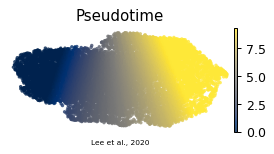

In [8]:
# sanitize non-serializable ElPiGraph uns entry (node positions kept; graph lives in uns['graph'])
sub.uns['epg'] = {'NodePositions': np.asarray(sub.uns['epg']['NodePositions'])}
sub.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = sub.obsm['X_umap_lin']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
plot = sub.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.text(.5,-.12,'Lee et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.h5ad + manifold.pdf')